# DevSphere AI & ML Internship — Week 5

## Model Evaluation + Tuning

**Project:** Comparative Machine Learning Evaluation and Hyperparameter Optimization

### Objective

Train multiple classification models, compare their performance using evaluation metrics, apply hyperparameter tuning, and select an optimized machine learning model.

### Workflow

**Dataset → Preprocessing → Multiple Models → Evaluation → Comparison → Hyperparameter Tuning → Optimized Model → Final Evaluation**

In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
dataset = load_breast_cancer()

X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

y = pd.Series(
    dataset.target,
    name="target"
)

print("Dataset Shape:", X.shape)
print("Features:", X.shape[1])
print("Samples:", X.shape[0])
print("Classes:", list(dataset.target_names))

Dataset Shape: (569, 30)
Features: 30
Samples: 569
Classes: [np.str_('malignant'), np.str_('benign')]


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 455
Testing Samples: 114


## 1. Multiple Model Evaluation

Three classification algorithms are evaluated:

- Logistic Regression
- Random Forest
- Support Vector Machine (SVM)

The models are compared using:

- Accuracy
- Precision
- Recall
- F1-Score

In [4]:
models = {
    "Logistic Regression": Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    max_iter=5000,
                    random_state=42
                )
            ),
        ]
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf")),
        ]
    ),
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions),
            "Recall": recall_score(y_test, predictions),
            "F1-Score": f1_score(y_test, predictions),
        }
    )

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.982456,0.986111,0.986111,0.986111
1,Random Forest,0.956140,0.958904,0.972222,0.965517
2,SVM,0.982456,0.986111,0.986111,0.986111


In [5]:
results_df.style.format(
    {
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}",
    }
).set_caption(
    "Classification Model Performance Comparison"
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,98.25%,98.61%,98.61%,98.61%
1,Random Forest,95.61%,95.89%,97.22%,96.55%
2,SVM,98.25%,98.61%,98.61%,98.61%


## 2. Model Performance Comparison

The results show how the three classification algorithms perform on the same unseen test dataset.

The comparison provides a baseline before hyperparameter optimization.

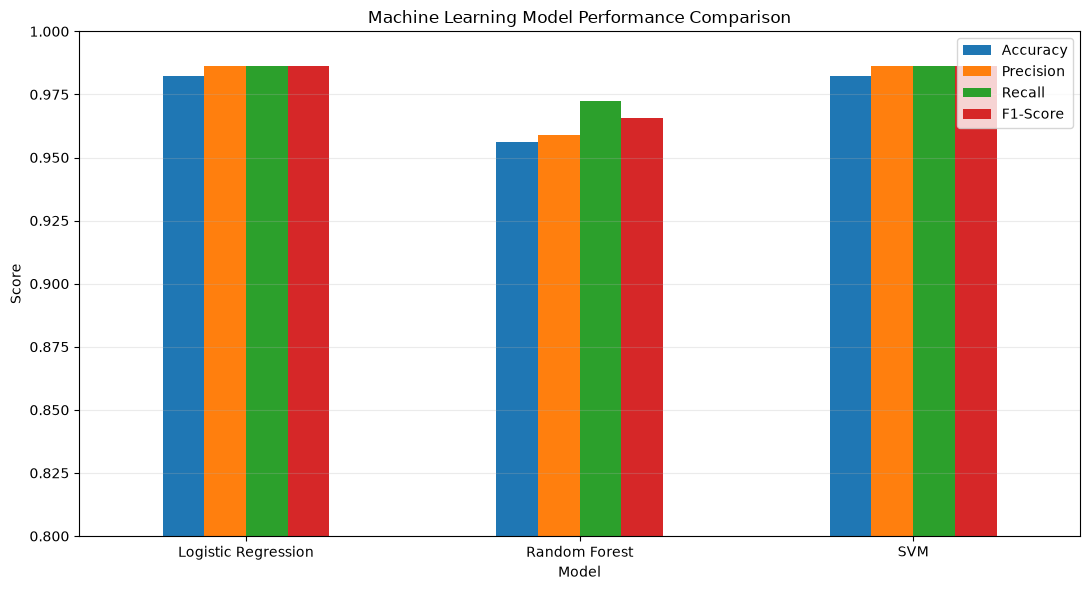

In [6]:
ax = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    "Machine Learning Model Performance Comparison"
)

ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0.80, 1.00)

ax.grid(
    axis="y",
    alpha=0.25
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Hyperparameter Tuning

Random Forest is selected for optimization using **GridSearchCV**.

The following hyperparameters are evaluated:

- Number of trees (`n_estimators`)
- Maximum tree depth (`max_depth`)
- Minimum samples required for splitting (`min_samples_split`)

Five-fold cross-validation is used to identify the strongest configuration.

In [ ]:
parameter_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42
    ),
    param_grid=parameter_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(f"{grid_search.best_score_:.4f}")

In [ ]:
optimized_predictions = best_model.predict(X_test)

optimized_accuracy = accuracy_score(
    y_test,
    optimized_predictions
)

optimized_precision = precision_score(
    y_test,
    optimized_predictions
)

optimized_recall = recall_score(
    y_test,
    optimized_predictions
)

optimized_f1 = f1_score(
    y_test,
    optimized_predictions
)

optimized_results = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
        ],
        "Score": [
            optimized_accuracy,
            optimized_precision,
            optimized_recall,
            optimized_f1,
        ],
    }
)

optimized_results.style.format(
    {"Score": "{:.2%}"}
).set_caption(
    "Optimized Random Forest Performance"
)

## 4. Optimized Model Evaluation

The tuned Random Forest model is evaluated against the unseen test dataset using accuracy, precision, recall, and F1-score.

In [ ]:
print(
    classification_report(
        y_test,
        optimized_predictions,
        target_names=dataset.target_names
    )
)

## 5. Confusion Matrix

The confusion matrix provides a detailed view of correct and incorrect predictions made by the optimized model.

In [ ]:
cm = confusion_matrix(
    y_test,
    optimized_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names
)

disp.plot()

plt.title(
    "Optimized Random Forest — Confusion Matrix"
)

plt.tight_layout()
plt.show()

## 6. Hyperparameter Search Results

The strongest hyperparameter configurations identified during five-fold cross-validation are examined below.

In [ ]:
cv_results = pd.DataFrame(
    grid_search.cv_results_
)

top_results = (
    cv_results[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_min_samples_split",
            "mean_test_score",
        ]
    ]
    .sort_values(
        "mean_test_score",
        ascending=False
    )
    .head(10)
)

top_results

In [ ]:
plt.figure(figsize=(12, 6))

plt.barh(
    range(len(top_results)),
    top_results["mean_test_score"]
)

labels = []

for _, row in top_results.iterrows():

    depth = row["param_max_depth"]

    if pd.isna(depth):
        depth = "None"

    labels.append(
        f"Trees={row['param_n_estimators']}, "
        f"Depth={depth}, "
        f"Split={row['param_min_samples_split']}"
    )

plt.yticks(
    range(len(top_results)),
    labels
)

plt.xlabel("Cross-Validation Accuracy")
plt.title("Top Hyperparameter Configurations")

plt.xlim(0.90, 1.00)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

# Conclusion

The Week 5 project successfully evaluated multiple classification algorithms and applied systematic hyperparameter tuning using GridSearchCV.

The final evaluation demonstrates the complete machine learning optimization workflow:

**Multiple Models → Performance Comparison → Hyperparameter Search → Optimized Model → Evaluation**

The optimized Random Forest model was successfully trained, evaluated, and saved for future use.